In [1]:
import sys, torch
print(sys.executable)
print(torch.__version__, torch.cuda.is_available())

/home/ad.msoe.edu/huelkes/sam_env/bin/python
2.15.0+cu132 True


In [2]:
import cv2, os, numpy as np
clip = "drive-download-20261031T172038Z-1-001/video_vial_fill_team-msoe-20261030T142247Z_20261030_145629_267244.mp4"
out = "frames/145629"; os.makedirs(out, exist_ok=True)
cap, i, k = cv2.VideoCapture(clip), 0, 0
while True:
    ok, f = cap.read()
    if not ok: break
    if i % 3 == 0:
        cv2.imwrite(f"{out}/{k:05d}.jpg", f); k += 1
    i += 1
print(k, "frames saved")

1257 frames saved


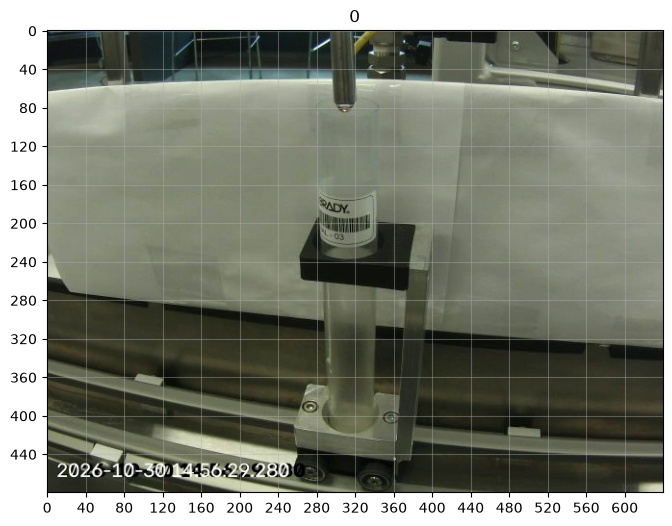

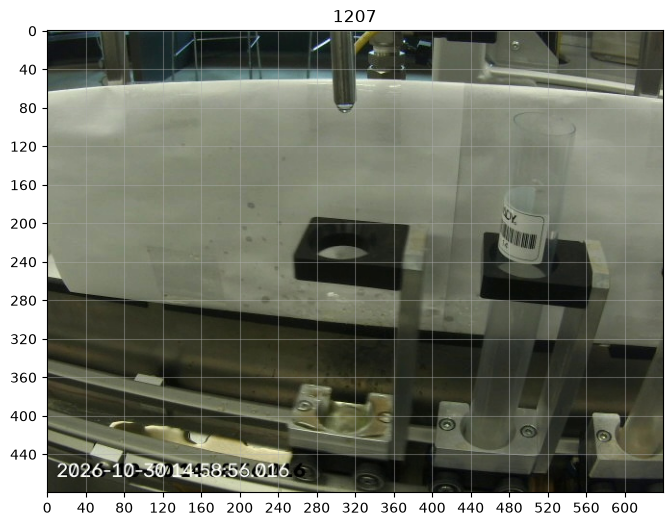

In [3]:
import matplotlib.pyplot as plt
for idx in [0, k - 50]:
    img = cv2.imread(f"{out}/{idx:05d}.jpg")[:, :, ::-1]
    plt.figure(figsize=(8, 6)); plt.imshow(img); plt.title(idx)
    plt.xticks(range(0, 640, 40)); plt.yticks(range(0, 480, 40)); plt.grid(alpha=.4)


In [7]:
import torch
from sam2.sam2_video_predictor import SAM2VideoPredictor
pred = SAM2VideoPredictor.from_pretrained("facebook/sam2.1-hiera-small")
print("SAM 2 loaded on", torch.cuda.get_device_name(0))

/home/ad.msoe.edu/huelkes/sam_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SAM 2 loaded on Tesla T4


In [ ]:
START, END = 0, 590                                     # this vial's window (10 fps frame numbers)
VIAL_BOX = np.array([300, 60, 360, 420], np.float32)    # x0,y0,x1,y1 around the vial on frame START

vial = {}
with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
    st = pred.init_state(video_path=out, offload_video_to_cpu=True)
    pred.add_new_points_or_box(st, frame_idx=START, obj_id=1, box=VIAL_BOX)
    for f, ids, logits in pred.propagate_in_video(st, start_frame_idx=START,
                                                  max_frame_num_to_track=END - START):
        vial[f] = (logits[0, 0] > 0).cpu().numpy()
print(len(vial), "vial masks")

frame loading (JPEG): 100%|██████████| 1257/1257 [00:36<00:00, 33.98it/s]
/home/ad.msoe.edu/huelkes/sam_env/lib/python3.12/site-packages/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/home/ad.msoe.edu/huelkes/sam_env/lib/python3.12/site-packages/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
propagate in video:  49%|████▉     | 292/591 [02:07<02:16,  2.19it/s]

In [ ]:
import pandas as pd

DE_THR    = 6.0   # CIELAB colour difference a row must exceed to count as liquid
GAP_ROWS  = 8     # this many unchanged rows in a row ends the liquid column
DARK_L    = 35    # rows darker than this in the empty vial (black holder) are skipped
MAX_SHIFT = 3     # px; frames where the vial moved sideways more than this are skipped

def lab(f):
    img = cv2.imread(f"{out}/{f:05d}.jpg").astype(np.float32) / 255
    return cv2.cvtColor(img, cv2.COLOR_BGR2LAB)          # L 0..100, a*/b* signed (assumes sRGB)

def row_medians(labimg, m):
    rows = np.full((m.shape[0], 3), np.nan, np.float32)
    for y in np.where(m.sum(1) >= 5)[0]:                  # need >= 5 vial pixels in the row
        rows[y] = np.median(labimg[y][m[y]], 0)           # median ignores the thin stream
    return rows

ref_m   = vial[START]
ref_row = row_medians(lab(START), ref_m)
ref_cx  = np.where(ref_m)[1].mean()
usable  = ~np.isnan(ref_row[:, 0]) & (ref_row[:, 0] > DARK_L)
bottom  = np.where(usable)[0].max()                       # lowest usable vial row

rows = []
for f in range(START, END):
    m = vial.get(f)
    r = {"frame_10fps": f, "video_frame": f * 3, "video_time_s": f * 3 / 30}
    if m is None or m.sum() < 500:
        rows.append({**r, "status": "no_vial"}); continue
    shift = abs(np.where(m)[1].mean() - ref_cx)
    r["vial_shift_px"] = round(float(shift), 1)
    if shift > MAX_SHIFT:
        rows.append({**r, "status": "vial_moving"}); continue

    cur = row_medians(lab(f), m & ref_m)
    dE  = np.linalg.norm(cur - ref_row, axis=1)           # NaN where a row isn't in both masks

    # walk up from the bottom; holder rows are skipped without breaking the run
    top, gap = None, 0
    for y in range(bottom, -1, -1):
        if not usable[y] or np.isnan(dE[y]):
            continue
        if dE[y] > DE_THR:
            top, gap = y, 0
        else:
            gap += 1
            if gap >= GAP_ROWS:
                break

    if top is None:
        rows.append({**r, "status": "empty", "fill_height_px": 0}); continue
    liq = [y for y in range(top, bottom + 1) if usable[y] and not np.isnan(dE[y]) and dE[y] > DE_THR]
    L, a, b = np.median(cur[liq], 0)
    rows.append({**r, "status": "ok", "fill_top_y": top, "fill_height_px": bottom - top,
                 "L": float(L), "a": float(a), "b": float(b), "dE_median": float(np.median(dE[liq]))})

lvl = pd.DataFrame(rows)
lvl.to_csv(f"level_{os.path.basename(out)}_{START}_{END}.csv", index=False)
print(lvl.status.value_counts())

In [ ]:

  ok = lvl[lvl.status == "ok"]
  fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
  ax[0].plot(ok.video_time_s, ok.fill_height_px, ".", ms=3); ax[0].set_ylabel("fill height (px)")
  ax[1].plot(ok.video_time_s, ok.a, ".", ms=3, label="a*")
  ax[1].plot(ok.video_time_s, ok.b, ".", ms=3, label="b*")
  ax[1].legend(); ax[1].set_xlabel("video time (s)")

  for f in np.linspace(START, END - 1, 5).astype(int):
      img = cv2.imread(f"{out}/{f:05d}.jpg")[:, :, ::-1].copy()
      m = vial.get(f)
      if m is not None:
          img[m] = (0.7 * img[m] + 0.3 * np.array([0, 255, 0])).astype(np.uint8)
      row = lvl.loc[lvl.frame_10fps == f].iloc[0]
      plt.figure(figsize=(4, 4)); plt.imshow(img[:450, 200:450])
      if row.status == "ok":
          plt.axhline(row.fill_top_y, color="m", lw=1.5)
      plt.title(f"{f}  {row.status}")


In [ ]:
import torch
from sam2.sam2_video_predictor import SAM2VideoPredictor
pred = SAM2VideoPredictor.from_pretrained("facebook/sam2.1-hiera-small")
VIAL_BOX   = np.array([280, 60, 350, 425], np.float32)   # x0,y0,x1,y1 on frame 0 – edit from cell 2
LIQ_FRAME  = k - 50                                       # a frame where the vial has liquid
LIQ_POINT  = np.array([[315, 380]], np.float32)           # a pixel inside the liquid – edit
masks = {}
with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
    st = pred.init_state(video_path=out, offload_video_to_cpu=True, offload_state_to_cpu=True)
    pred.add_new_points_or_box(st, frame_idx=0, obj_id=1, box=VIAL_BOX)
    pred.add_new_points_or_box(st, frame_idx=LIQ_FRAME, obj_id=2,
                               points=LIQ_POINT, labels=np.array([1], np.int32))
    for rev in (False, True):
        for f, ids, logits in pred.propagate_in_video(st, reverse=rev):
            for j, oid in enumerate(ids):
                masks[(f, oid)] = (logits[j, 0] > 0).cpu().numpy()

In [ ]:
import pandas as pd
rows = []
for f in range(k):
    liq = masks.get((f, 2))
    img = cv2.imread(f"{out}/{f:05d}.jpg")
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    r = {"frame_10fps": f, "video_frame": f * 3}
    if liq is not None and liq.any():
        ys = np.where(liq.any(1))[0]
        L, a, b = np.median(lab[liq], 0)
        r.update(liq_top_y=ys.min(), liq_bottom_y=ys.max(), liq_area_px=int(liq.sum()),
                 L=L * 100 / 255, a=a - 128, b=b - 128)
    rows.append(r)
df = pd.DataFrame(rows); df.to_csv("sam_145629.csv", index=False); df.plot(x="frame_10fps", y="liq_area_px")

In [ ]:
for f in [0, k // 4, k // 2, 3 * k // 4, k - 1]:
     img = cv2.imread(f"{out}/{f:05d}.jpg")[:, :, ::-1].copy()
     for oid, col in [(1, (0, 255, 0)), (2, (255, 0, 255))]:
         m = masks.get((f, oid))
         if m is not None: img[m] = (0.5 * img[m] + 0.5 * np.array(col)).astype(np.uint8)
     plt.figure(figsize=(5, 4)); plt.imshow(img); plt.title(f)